# Assignment 07: Neural Network with Backpropagation
**Course:** ECE 5831 - Pattern Recognition and Neural Networks  
**Author:** Michel Temgoua  
**Date:** Fall 2026  

## Overview
This notebook implements a Two-Layer Neural Network (`TwoLayerNetBackprop`) trained from scratch on the MNIST handwritten digit dataset using analytical **Backpropagation** with the ReLU activation function. 

### Key Objectives:
1. Implement forward propagation and analytical gradient calculation using Backpropagation.
2. Load and preprocess the MNIST dataset from `tensorflow.keras.datasets`.
3. Train the neural network using mini-batch Stochastic Gradient Descent (SGD).
4. Evaluate model performance using cross-entropy loss, training accuracy, test accuracy, and sample visual predictions.

In [1]:
# Import core computational, visualization, and dataset modules
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

# Verify environment setup
print("NumPy version:", np.__version__)
print("MNIST dataset module successfully imported from Keras.")

NumPy version: 2.4.6
MNIST dataset module successfully imported from Keras.


## Section 1: Two-Layer Neural Network Class with Backpropagation

We define `TwoLayerNetBackprop` using:
- **Input Layer:** 784 nodes ($28 \times 28$ pixels)
- **Hidden Layer:** 100 nodes with **ReLU** activation
- **Output Layer:** 10 nodes (digits 0–9) with **Softmax** activation
- **Loss Function:** Categorical Cross-Entropy Loss

In [2]:
class TwoLayerNetBackprop:
    def __init__(self, input_size=28*28, hidden_size=100, output_size=10, weight_init_std=0.01):
        """
        Initialize network weights and biases.
        Weights are initialized using Gaussian random values scaled by weight_init_std.
        Biases are initialized to zeros.
        """
        self.params = {}
        self.params["w1"] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params["b1"] = np.zeros(hidden_size)
        self.params["w2"] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params["b2"] = np.zeros(output_size)

    def relu(self, s):
        """Rectified Linear Unit (ReLU) activation function."""
        return np.maximum(0, s)

    def relu_grad(self, s):
        """Derivative of ReLU activation function."""
        grad = np.zeros_like(s)
        grad[s > 0] = 1.0
        return grad

    def softmax(self, s):
        """Numerically stable Softmax activation function."""
        if s.ndim == 1:
            s = s - np.max(s)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s)
        else:
            s = s - np.max(s, axis=1, keepdims=True)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s, axis=1, keepdims=True)

    def predict(self, x):
        """Forward propagation to compute class probability distribution (yhat)."""
        w1, b1 = self.params["w1"], self.params["b1"]
        w2, b2 = self.params["w2"], self.params["b2"]

        # Hidden Layer
        a1 = x @ w1 + b1
        z1 = self.relu(a1)

        # Output Layer
        a2 = z1 @ w2 + b2
        yhat = self.softmax(a2)
        return yhat

    def cross_entropy_error(self, y, yhat):
        """Computes average Categorical Cross-Entropy loss over mini-batch."""
        if y.ndim == 1:
            y = y.reshape(1, y.size)
            yhat = yhat.reshape(1, yhat.size)
        batch_size = y.shape[0]
        return -np.sum(y * np.log(yhat + 1e-7)) / batch_size

    def loss(self, x, y):
        """Computes loss given input batch x and target batch y (one-hot)."""
        yhat = self.predict(x)
        return self.cross_entropy_error(y, yhat)

    def gradient(self, x, y):
        """
        Analytical Backpropagation algorithm.
        Computes exact partial derivatives (dw1, db1, dw2, db2) efficiently.
        """
        w1, b1 = self.params["w1"], self.params["b1"]
        w2, b2 = self.params["w2"], self.params["b2"]

        if x.ndim == 1:
            x = x.reshape(1, -1)
        if y.ndim == 1:
            y = y.reshape(1, -1)

        batch_size = x.shape[0]

        # 1. FORWARD PASS
        a1 = x @ w1 + b1
        z1 = self.relu(a1)
        a2 = z1 @ w2 + b2
        yhat = self.softmax(a2)

        # 2. BACKWARD PASS (BACKPROPAGATION)
        # Softmax + Cross-Entropy combined loss gradient
        da2 = (yhat - y) / batch_size

        # Layer 2 Gradients (Output -> Hidden)
        dw2 = z1.T @ da2
        db2 = np.sum(da2, axis=0)

        # Layer 1 Gradients (Hidden -> Input)
        dz1 = da2 @ w2.T
        da1 = dz1 * self.relu_grad(a1)
        dw1 = x.T @ da1
        db1 = np.sum(da1, axis=0)

        # Store and return gradient dictionary
        grad = {
            "w1": dw1,
            "b1": db1,
            "w2": dw2,
            "b2": db2
        }
        return grad

## Section 2: MNIST Dataset Loading & Preprocessing

1. Load raw MNIST image dataset from Keras (`mnist.load_data()`).
2. Reshape $28 \times 28$ image matrices into 784-dimensional flat vectors.
3. Normalize pixel values from $[0, 255]$ range to $[0.0, 1.0]$ float32 range.
4. One-hot encode integer labels (0–9) for training compatibility.

In [3]:
# Load MNIST dataset
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = mnist.load_data()

print("Raw Dataset Dimensions:")
print("X_train shape:", X_train_raw.shape)
print("y_train shape:", y_train_raw.shape)
print("X_test shape :", X_test_raw.shape)
print("y_test shape :", y_test_raw.shape)

# Flatten and normalize image feature matrices
X_train = X_train_raw.reshape(60000, 784).astype("float32") / 255.0
X_test = X_test_raw.reshape(10000, 784).astype("float32") / 255.0

# One-hot encode labels
y_train_onehot = np.eye(10)[y_train_raw]
y_test_onehot = np.eye(10)[y_test_raw]

print("\nPreprocessed Dimensions:")
print("X_train flattened & normalized:", X_train.shape)
print("X_test flattened & normalized :", X_test.shape)
print("y_train one-hot shape          :", y_train_onehot.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Raw Dataset Dimensions:
X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape : (10000, 28, 28)
y_test shape : (10000,)

Preprocessed Dimensions:
X_train flattened & normalized: (60000, 784)
X_test flattened & normalized : (10000, 784)
y_train one-hot shape          : (60000, 10)


## Section 3: Training TwoLayerNetBackprop

We train the network using **Stochastic Mini-Batch Gradient Descent**:
- **Epochs:** 10
- **Batch Size:** 64
- **Learning Rate:** 0.1

In [4]:
# Hyperparameters
epochs = 10
learning_rate = 0.1
batch_size = 64

# Track metric history
train_loss_list = []
train_acc_list = []

# Instantiate model
network = TwoLayerNetBackprop(input_size=28*28, hidden_size=100, output_size=10)

print("Starting Neural Network Training via Backpropagation...\n")

for epoch in range(epochs):
    # Shuffle dataset per epoch
    indices = np.random.permutation(len(X_train))
    X_train_shuffled = X_train[indices]
    y_train_shuffled = y_train_onehot[indices]

    # Mini-batch gradient descent loop
    for i in range(0, len(X_train), batch_size):
        x_batch = X_train_shuffled[i:i+batch_size]
        y_batch = y_train_shuffled[i:i+batch_size]

        # Compute exact gradients using Backpropagation
        grad = network.gradient(x_batch, y_batch)

        # Parameter update rule: W = W - lr * grad
        for key in network.params.keys():
            network.params[key] -= learning_rate * grad[key]

    # Compute loss and accuracy for monitoring
    loss = network.loss(X_train, y_train_onehot)
    train_loss_list.append(loss)

    y_pred = network.predict(X_train)
    predicted_class = np.argmax(y_pred, axis=1)
    accuracy = np.mean(predicted_class == y_train_raw)
    train_acc_list.append(accuracy)

    print(f"Epoch: {epoch+1:2d}/{epochs} | Loss: {loss:.4f} | Training Accuracy: {accuracy:.4f}")

print("\nTraining completed successfully!")

Starting Neural Network Training via Backpropagation...

Epoch:  1/10 | Loss: 0.2860 | Training Accuracy: 0.9161
Epoch:  2/10 | Loss: 0.2092 | Training Accuracy: 0.9402
Epoch:  3/10 | Loss: 0.1667 | Training Accuracy: 0.9520
Epoch:  4/10 | Loss: 0.1362 | Training Accuracy: 0.9613
Epoch:  5/10 | Loss: 0.1152 | Training Accuracy: 0.9682
Epoch:  6/10 | Loss: 0.0934 | Training Accuracy: 0.9742
Epoch:  7/10 | Loss: 0.0877 | Training Accuracy: 0.9757
Epoch:  8/10 | Loss: 0.0759 | Training Accuracy: 0.9789
Epoch:  9/10 | Loss: 0.0676 | Training Accuracy: 0.9811
Epoch: 10/10 | Loss: 0.0670 | Training Accuracy: 0.9811

Training completed successfully!


## Section 4: Training Performance Visualization

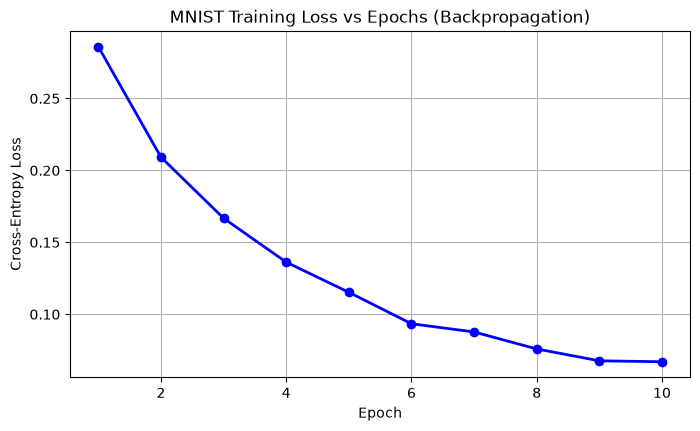

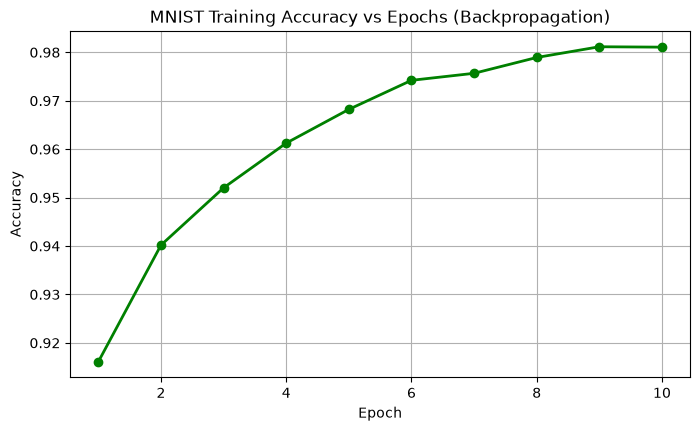

In [5]:
# Plot Training Loss Curve
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, epochs + 1), train_loss_list, marker="o", color="blue", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("MNIST Training Loss vs Epochs (Backpropagation)")
plt.grid(True)
plt.show()

# Plot Training Accuracy Curve
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, epochs + 1), train_acc_list, marker="o", color="green", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MNIST Training Accuracy vs Epochs (Backpropagation)")
plt.grid(True)
plt.show()

## Section 5: Model Evaluation & Predictions on Test Set

FINAL TEST SET ACCURACY: 97.37% (0.9737)


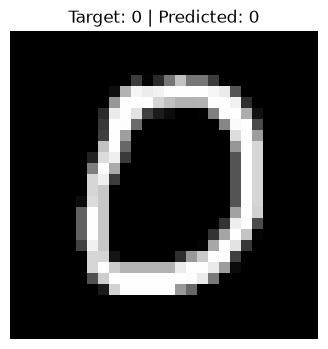

Sample #10 -> Target: 0, Predicted Digit: 0


In [6]:
# Evaluate model on 10,000 unseen test samples
y_test_pred = network.predict(X_test)
predicted_test_class = np.argmax(y_test_pred, axis=1)
test_accuracy = np.mean(predicted_test_class == y_test_raw)

print("=" * 45)
print(f"FINAL TEST SET ACCURACY: {test_accuracy * 100:.2f}% ({test_accuracy:.4f})")
print("=" * 45)

# Visual Sample Prediction Test (Sample Index 10)
sample_idx = 10
sample_image = X_test_raw[sample_idx]
predicted_label = np.argmax(y_test_pred[sample_idx])
true_label = y_test_raw[sample_idx]

plt.figure(figsize=(4, 4))
plt.imshow(sample_image, cmap="gray")
plt.title(f"Target: {true_label} | Predicted: {predicted_label}")
plt.axis("off")
plt.show()

print(f"Sample #{sample_idx} -> Target: {true_label}, Predicted Digit: {predicted_label}")